# Assignment 03 PCD (Segmentation and Morphological Processing)

### Nama: Jundan Saiful Haq
### NIM : 25/560768/PA/23633

# 1. Import Depedencies

In [18]:
from google.colab import drive
import os
import cv2
import numpy as np
import matplotlib.pyplot as plt
import time

# mount drive
drive.mount('/content/drive')

# config visualisasi matplotlib
plt.rcParams['figure.dpi'] = 120
plt.rcParams['image.cmap'] = 'gray'

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


# 2. Load Citra (via mount drive)

Memuat citra uji koin dari Google Drive.

Foto berhasil dimuat: 23560e97ad.jpg
Dimensi Citra Asli (RGB) : 500x314x3
Dimensi Citra Grayscale  : 500x314


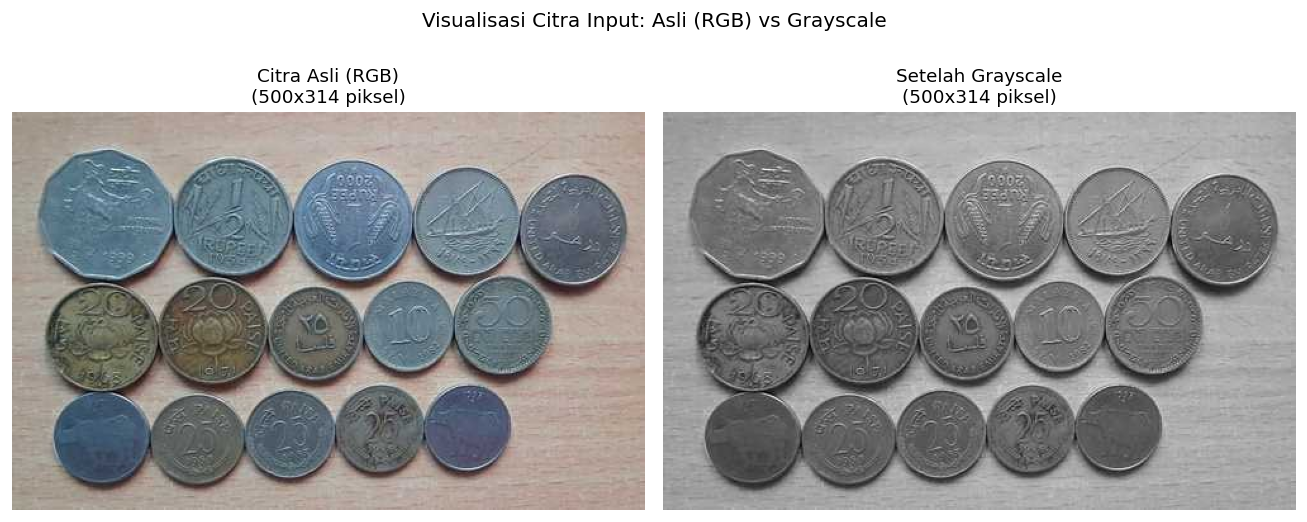

In [19]:
DRIVE_IMG_DIR = "/content/drive/MyDrive/Tugas/Ilmu_Komputer/Semester_3/PCD/Assignment03/images"

image_path = os.path.join(DRIVE_IMG_DIR, "23560e97ad.jpg")

if not os.path.exists(image_path):
  raise FileNotFoundError(f"File citra tidak ditemukan di: {image_path}")

# read citra berwarna asli (format BGR)
img_bgr = cv2.imread(image_path)
if img_bgr is None:
  raise ValueError(f"Gagal memuat citra dari {image_path}")

# konversi BGR ke RGB untuk visualisasi matplotlib yang akurat
img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)

# konversi ke grayscale
img_gray = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2GRAY)

print(f"Foto berhasil dimuat: {os.path.basename(image_path)}")
print(f"Dimensi Citra Asli (RGB) : {img_rgb.shape[1]}x{img_rgb.shape[0]}x{img_rgb.shape[2]}")
print(f"Dimensi Citra Grayscale  : {img_gray.shape[1]}x{img_gray.shape[0]}")

# display citra asli dan setelah grayscale
fig, axes = plt.subplots(1, 2, figsize=(11, 4.5))

axes[0].imshow(img_rgb)
axes[0].set_title(f"Citra Asli (RGB)\n({img_rgb.shape[1]}x{img_rgb.shape[0]} piksel)", fontsize=11)
axes[0].axis('off')

axes[1].imshow(img_gray, cmap='gray')
axes[1].set_title(f"Setelah Grayscale\n({img_gray.shape[1]}x{img_gray.shape[0]} piksel)", fontsize=11)
axes[1].axis('off')

plt.suptitle("Visualisasi Citra Input: Asli (RGB) vs Grayscale", fontsize=12, y=1.02)
plt.tight_layout()
plt.show()

# 3. Global Thresholding Segmentation using Otsu

Algoritma Otsu mencari nilai threshold optimal T yang memaksimalkan variansi antar-kelas (between-class variance) pada histogram 256 tingkat keabuan.
Ditambahkan juga border sampling heuristic untuk memastikan konsistensi polaritas citra biner (objek target koin = 1, latar belakang meja = 0) secara otomatis.

In [20]:
def manual_otsu_threshold(gray_img: np.ndarray):
  hist = np.zeros(256, dtype=np.int64)
  flat = gray_img.ravel()
  for val in flat:
    hist[val] += 1

  total_pixels = flat.size
  prob = hist / total_pixels

  weight0 = np.cumsum(prob)
  weight1 = 1.0 - weight0

  intensity_axis = np.arange(256)
  cum_mean = np.cumsum(prob * intensity_axis)
  global_mean = cum_mean[-1]

  between_class_variance = np.zeros(256, dtype=np.float64)

  for t in range(256):
    w0 = weight0[t]
    w1 = weight1[t]
    if w0 > 0 and w1 > 0:
      u0 = cum_mean[t] / w0
      u1 = (global_mean - cum_mean[t]) / w1
      between_class_variance[t] = w0 * w1 * ((u0 - u1) ** 2)

  optimal_threshold = int(np.argmax(between_class_variance))
  return optimal_threshold, between_class_variance

def manual_otsu_segmentation(gray_img: np.ndarray):
  t_opt, var_b = manual_otsu_threshold(gray_img)

  # binarisasi dasar
  binary = (gray_img > t_opt).astype(np.uint8)

  # border sampling heuristic
  top = binary[0, :]
  bottom = binary[-1, :]
  left = binary[:, 0]
  right = binary[:, -1]
  border_pixels = np.concatenate([top, bottom, left, right])

  is_inverted = False
  # jika tepi mayoritas putih (1), berarti background terang, sehingga perlu di-invert
  if np.mean(border_pixels) > 0.5:
    binary = 1 - binary
    is_inverted = True

  return binary, t_opt, var_b, is_inverted

# 4. Zero Padding (Spatial 2D)

Fungsi padding manual tanpa library untuk menangani perbatasan citra pada proses sliding window morfologi.

In [21]:
def manual_pad(image: np.ndarray, pad_size: int = 1, pad_value: int = 0) -> np.ndarray:
  h, w = image.shape
  padded = np.full((h + 2 * pad_size, w + 2 * pad_size), pad_value, dtype=image.dtype)
  padded[pad_size:h + pad_size, pad_size:w + pad_size] = image
  return padded

# 5. Morphological Operations

Implementasi operasi dasar morfologi (Erosion & Dilation) dan operasi gabungan (Opening & Closing) menggunakan sliding window 2D yang berfungsi untuk enhance hasil segmentation yang tidak selalu sempurna.

In [22]:
def manual_erosion(binary_img: np.ndarray, kernel_size: int = 5) -> np.ndarray:
  h, w = binary_img.shape
  pad_size = kernel_size // 2

  # padding nilai 1 agar tepi objek tidak terkikis oleh batas citra luar
  padded = manual_pad(binary_img, pad_size=pad_size, pad_value=1)
  output = np.zeros((h, w), dtype=np.uint8)

  for i in range(h):
    for j in range(w):
      patch = padded[i : i + kernel_size, j : j + kernel_size]
      if np.all(patch == 1):
        output[i, j] = 1
      else:
        output[i, j] = 0

  return output

def manual_dilation(binary_img: np.ndarray, kernel_size: int = 5) -> np.ndarray:
  h, w = binary_img.shape
  pad_size = kernel_size // 2

  # padding nilai 0 untuk area luar background
  padded = manual_pad(binary_img, pad_size=pad_size, pad_value=0)
  output = np.zeros((h, w), dtype=np.uint8)

  for i in range(h):
    for j in range(w):
      patch = padded[i : i + kernel_size, j : j + kernel_size]
      if np.any(patch == 1):
        output[i, j] = 1
      else:
        output[i, j] = 0

  return output

def manual_opening(binary_img: np.ndarray, kernel_size: int = 5) -> np.ndarray:
  # Opening = Erosi dilanjutkan Dilatasi
  return manual_dilation(manual_erosion(binary_img, kernel_size=kernel_size), kernel_size=kernel_size)

def manual_closing(binary_img: np.ndarray, kernel_size: int = 5) -> np.ndarray:
  # Closing = Dilatasi dilanjutkan Erosi
  return manual_erosion(manual_dilation(binary_img, kernel_size=kernel_size), kernel_size=kernel_size)

# 6. Batch Segmentation & Morphological Pipeline Experiment

In [23]:
# 1. Eksekusi segmentasi Otsu
t0 = time.time()
binary_raw, t_opt, var_b, is_inverted = manual_otsu_segmentation(img_gray)
t_otsu = time.time() - t0
print(f"-> Otsu Segmentation : {t_otsu:.2f} detik (T = {t_opt}, Invert = {is_inverted})")

kernel_size = 5

# 2. Operasi dilatasi saja
t0 = time.time()
res_dilated = manual_dilation(binary_raw, kernel_size=kernel_size)
t_dil = time.time() - t0
print(f"-> Dilation ({kernel_size}x{kernel_size})  : {t_dil:.2f} detik")

# 3. Operasi erosi saja
t0 = time.time()
res_eroded = manual_erosion(binary_raw, kernel_size=kernel_size)
t_ero = time.time() - t0
print(f"-> Erosion ({kernel_size}x{kernel_size})   : {t_ero:.2f} detik")

# 4. Operasi opening saja
t0 = time.time()
res_opened = manual_opening(binary_raw, kernel_size=kernel_size)
t_open = time.time() - t0
print(f"-> Opening ({kernel_size}x{kernel_size})   : {t_open:.2f} detik")

# 5. Operasi closing saja
t0 = time.time()
res_closed = manual_closing(binary_raw, kernel_size=kernel_size)
t_close = time.time() - t0
print(f"-> Closing ({kernel_size}x{kernel_size})   : {t_close:.2f} detik")

# 6. Pipeline optimal: Closing terlebih dahulu lalu Opening
t0 = time.time()
res_closed_then_opened = manual_opening(res_closed, kernel_size=kernel_size)
t_pipe1 = time.time() - t0
print(f"-> Closing -> Opening : {t_pipe1:.2f} detik")

# 7. Kontra pipeline: Opening terlebih dahulu lalu Closing
t0 = time.time()
res_opened_then_closed = manual_closing(res_opened, kernel_size=kernel_size)
t_pipe2 = time.time() - t0
print(f"-> Opening -> Closing : {t_pipe2:.2f} detik")

-> Otsu Segmentation : 0.07 detik (T = 133, Invert = True)
-> Dilation (5x5)  : 1.22 detik
-> Erosion (5x5)   : 1.08 detik
-> Opening (5x5)   : 2.61 detik
-> Closing (5x5)   : 2.61 detik
-> Closing -> Opening : 2.30 detik
-> Opening -> Closing : 2.30 detik


# 7. Visualisasi Hasil Segmentasi dan Morfologi

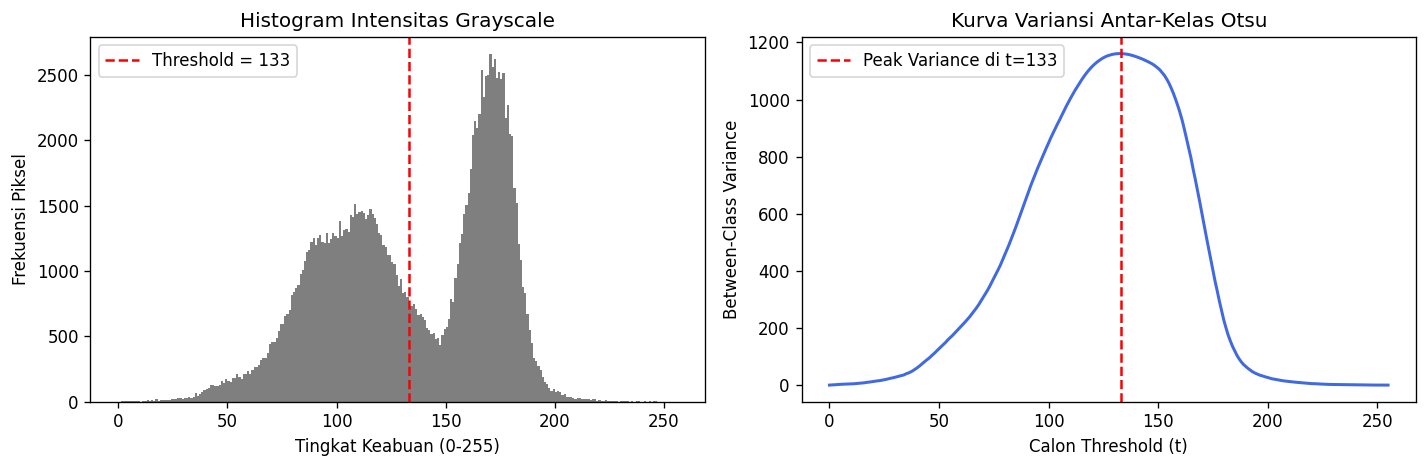

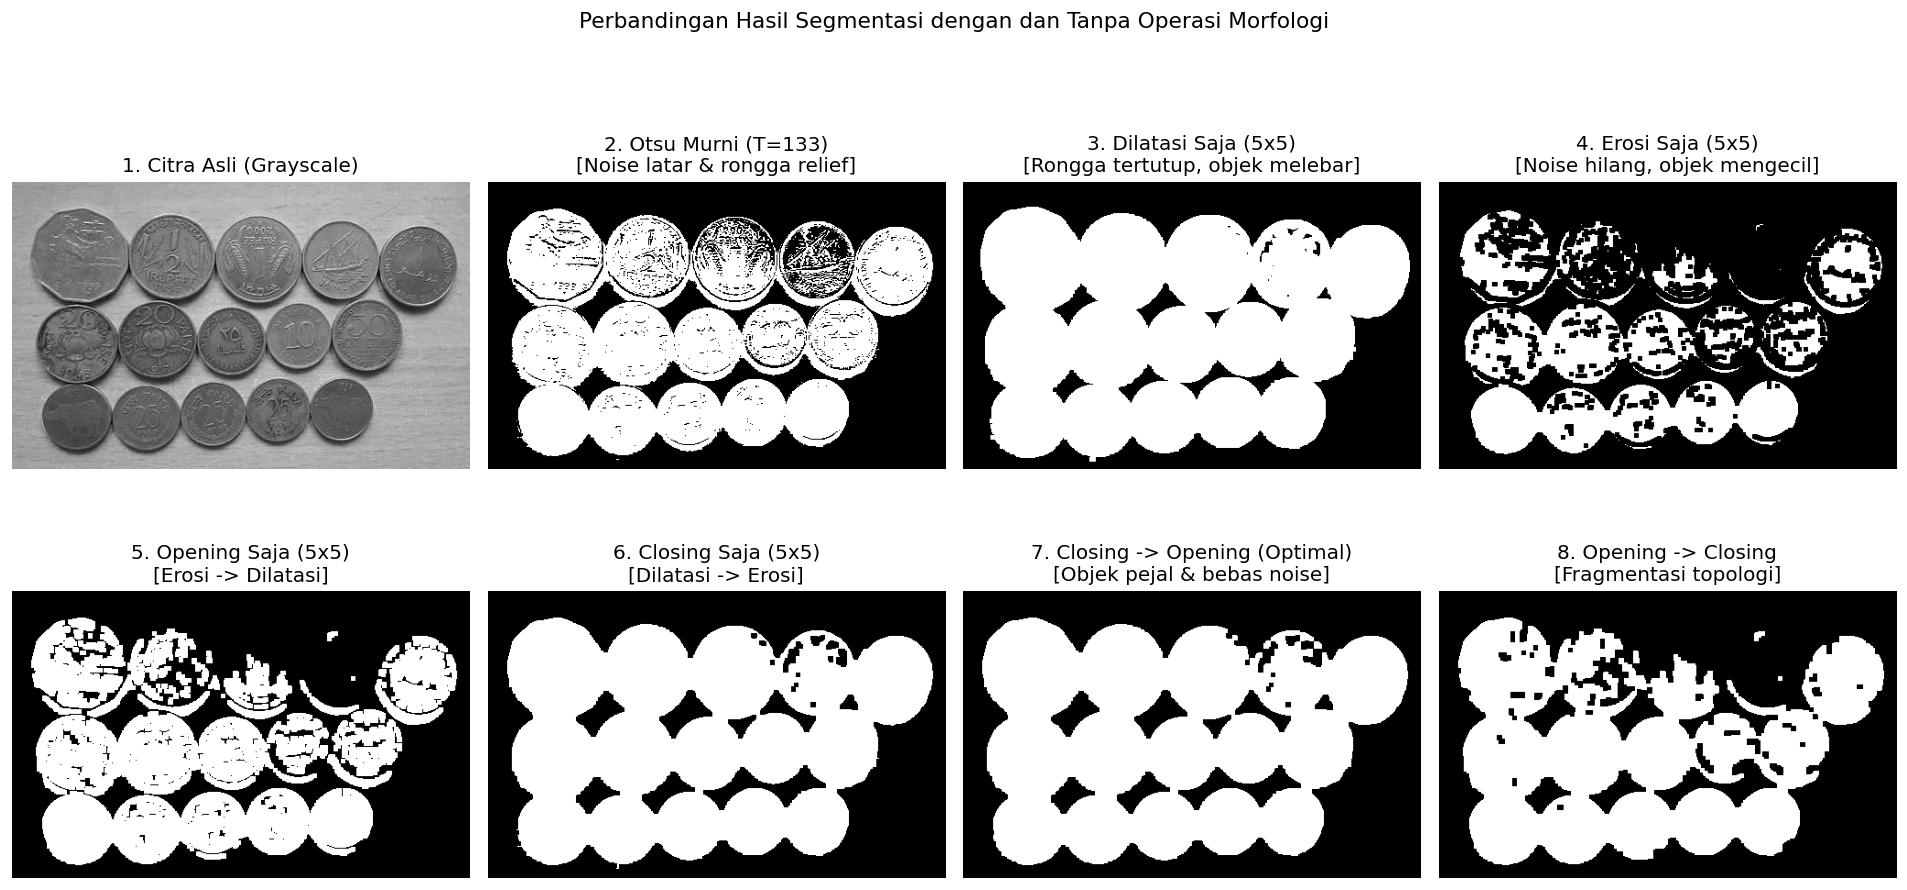

In [24]:
# Visualisasi 1: Kurva Variansi Antar-Kelas Otsu
plt.figure(figsize=(12, 4))

plt.subplot(1, 2, 1)
plt.hist(img_gray.ravel(), bins=256, range=(0, 256), color='dimgray', alpha=0.85)
plt.axvline(t_opt, color='red', linestyle='--', linewidth=1.5, label=f'Threshold = {t_opt}')
plt.title("Histogram Intensitas Grayscale")
plt.xlabel("Tingkat Keabuan (0-255)")
plt.ylabel("Frekuensi Piksel")
plt.legend()

plt.subplot(1, 2, 2)
plt.plot(var_b, color='royalblue', linewidth=1.8)
plt.axvline(t_opt, color='red', linestyle='--', linewidth=1.5, label=f'Peak Variance di t={t_opt}')
plt.title("Kurva Variansi Antar-Kelas Otsu")
plt.xlabel("Calon Threshold (t)")
plt.ylabel("Between-Class Variance")
plt.legend()

plt.tight_layout()
plt.show()

# Visualisasi 2: Komparasi Grid 2x4
fig, axes = plt.subplots(2, 4, figsize=(16, 8))

axes[0, 0].imshow(img_gray, cmap='gray')
axes[0, 0].set_title("1. Citra Asli (Grayscale)")
axes[0, 0].axis('off')

axes[0, 1].imshow(binary_raw, cmap='gray')
axes[0, 1].set_title(f"2. Otsu Murni (T={t_opt})\n[Noise latar & rongga relief]")
axes[0, 1].axis('off')

axes[0, 2].imshow(res_dilated, cmap='gray')
axes[0, 2].set_title(f"3. Dilatasi Saja ({kernel_size}x{kernel_size})\n[Rongga tertutup, objek melebar]")
axes[0, 2].axis('off')

axes[0, 3].imshow(res_eroded, cmap='gray')
axes[0, 3].set_title(f"4. Erosi Saja ({kernel_size}x{kernel_size})\n[Noise hilang, objek mengecil]")
axes[0, 3].axis('off')

axes[1, 0].imshow(res_opened, cmap='gray')
axes[1, 0].set_title(f"5. Opening Saja ({kernel_size}x{kernel_size})\n[Erosi -> Dilatasi]")
axes[1, 0].axis('off')

axes[1, 1].imshow(res_closed, cmap='gray')
axes[1, 1].set_title(f"6. Closing Saja ({kernel_size}x{kernel_size})\n[Dilatasi -> Erosi]")
axes[1, 1].axis('off')

axes[1, 2].imshow(res_closed_then_opened, cmap='gray')
axes[1, 2].set_title(f"7. Closing -> Opening (Optimal)\n[Objek pejal & bebas noise]")
axes[1, 2].axis('off')

axes[1, 3].imshow(res_opened_then_closed, cmap='gray')
axes[1, 3].set_title(f"8. Opening -> Closing\n[Fragmentasi topologi]")
axes[1, 3].axis('off')

plt.suptitle("Perbandingan Hasil Segmentasi dengan dan Tanpa Operasi Morfologi", fontsize=13, y=1.02)
plt.tight_layout()
plt.show()